#**Analisi Preliminare Fase 0**
1. Attivare il Runtime della GPU e verificare che funzioni.
2. Caricare il dataset MNIST (cercare sulla documentazione come fare) e capirne le caratteristiche, eseguendo anche l'esplorazione del dataset.
3. Modelli Logistic Regression e DenseNet CNN compatibile con il dataset, eseguire i calcoli di parametri e output shape.
4. Allenare la Logistic Regression e la CNN.
5. Testare la CNN e calcolare l'accuracy. <br>

Vedere appunti e codice dei notebook <br>
1. profai_11_XAI_esercizi_05_05_Computer_Vision_Q_mio <br>
2. profai_11_XAI_esercizi_05_05_Computer_Vision_A_tutor

#**TEST FASE 0 CON CLAUDE** <br>

Come eseguirlo

Su Colab con runtime GPU, copia i file nel repository (o fai il commit e poi il clone). Poi:

!git clone https://github.com/francescofrigerio/profai_11_xai_prj_bancavirtuosa
%cd profai_11_xai_prj_bancavirtuosa-main/1_design/fase_0/
!pip -q install captum lime shap scikit-image
%run phase0_checks.py --quick
%run phase0_checks.py

Usa %run e non !python: solo nello stesso kernel il controllo 1 può rilevare se pip ha cambiato pacchetti già caricati e serve riavviare il runtime.

Prima --quick: pesi casuali, dati minuscoli, pochi minuti. Serve a scovare errori nello script.
I risultati non sono validi per le decisioni, e il file prodotto è separato (_quick).

Poi il run completo: l’ordine è 1, 2, 5, 6, 3, 4, 7, 8, 11, 12, 9, 10. Il controllo 6 viene prima di 3, 4, 11 e 12
perché salva la testa addestrata che quei controlli usano. Il controllo 6 con le due varianti è il più lungo.

Cosa mi serve da te
L’output della console del --quick (o gli errori, se ce ne sono), così correggo lo script prima del run completo.

Poi phase0_results.json, phase0_summary.md e le 5 figure phase0_*.png.
Quattro controlli (5, 7, 8, 12) hanno un esito che va giudicato a occhio: sono contrassegnati REVIEW e il riepilogo li elenca.

L’ok sulle correzioni dell’errata ancora in stato P. Quelle che incidono di più sul resto sono E03
(regola di ricampionamento), E07 e E08 (campione e galleria).

Alla chiusura della tappa 0 dimostrerò i criteri concordati:
ogni controllo PASS, oppure FAIL
con una decisione documentata.
 A quel punto parte la tappa 1.


#HOW TO RUN (Google Colab, GPU runtime) : --quick

Cloning into 'profai_11_xai_prj_bancavirtuosa'...
remote: Enumerating objects: 62, done.
remote: Counting objects: 100% (62/62), done.
remote: Compressing objects: 100% (56/56), done.
remote: Total 62 (delta 16), reused 39 (delta 4), pack-reused 0 (from 0)
Receiving objects: 100% (62/62), 112.19 KiB | 941.00 KiB/s, done.
Resolving deltas: 100% (16/16), done.
/content/profai_11_xai_prj_bancavirtuosa/profai_11_xai_prj_bancavirtuosa/profai_11_xai_prj_bancavirtuosa/1_design/fase_0
QUICK RUN: random weights and tiny data. Results are NOT valid for decisions.

=== CHECK 1: Environment, versions, GPU, no-restart ====================
  [PASS] all required libraries import: torch=2.11.0+cu130, torchvision=0.26.0+cu130, numpy=2.1.3, scipy=1.16.3, scikit-learn=1.6.1, captum=0.9.0, lime=0.2.0.1, shap=0.52.0, scikit-image=0.25.2, matplotlib=3.10.0, pandas=2.2.3, seaborn=0.13.2
  [PASS] no package changed after being loaded (no restart needed)
  [PASS] torch <-> numpy round trip works (ABI compatibl

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.2MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 494kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.63MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 14.1MB/s]


  [INFO] sklearn 1.6.1; LR input range [0.0, 1.0], 784 features, not standardized
  [INFO] C=1.0: fit 2.1s, n_iter 104, val acc 0.8600
  [PASS] C=1.0: ConvergenceWarning=False
  [WARN] C=1.0: validation accuracy 0.8600 (design expects ~0.92, range 0.9-0.94)
  [PASS] C=1.0: logit = sum(w*x)+b exactly (max error 0.0e+00)
  [PASS] C=1.0: classes_ == 0..9 (coefficient rows aligned)
  [PASS] C=1.0: per-pixel sum of coefficients over classes max 9.0e-15 (~0 with l2: relative and absolute coefficients coincide)
  [INFO] C=1.0: other warnings raised: ['DeprecationWarning']
  figure saved: outputs/phase0/phase0_05_lr_global_maps_C1.0.png


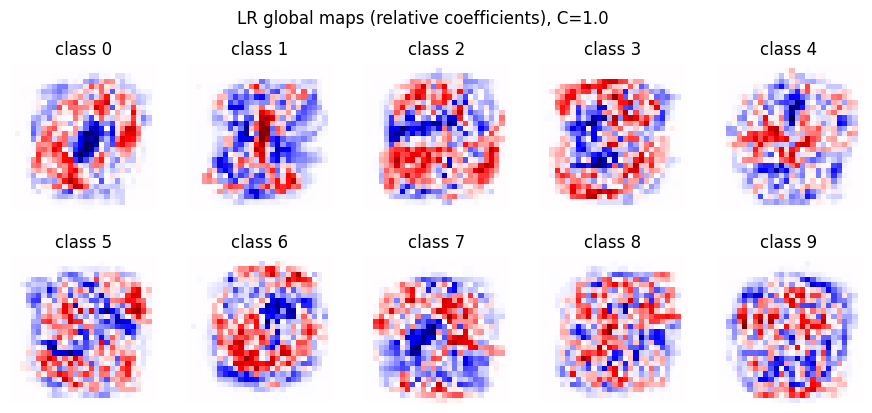

  [REVIEW] look at the phase0_05_lr_global_maps_*.png: are the maps readable (smooth, digit-shaped) at the configured LR_C?
  -> check 5 status: WARN (6.3s)

=== CHECK 6: Frozen DenseNet training (time, accuracy, BatchNorm) ====================
  [PASS] tensor preprocessing vs torchvision PIL pipeline: max diff 0.0174, mean 0.00116 (normalized units; uint8 rounding alone is ~0.009)
  [INFO] training DESIGN variant: 1 epoch(s), batch 64, lr 0.001, backbone frozen, BatchNorm in eval
    epoch 1: train loss 2.3330 acc 0.1165 | val loss 2.3322 acc 0.1580 | 2s + 1s
  [PASS] trainable parameters: 10250 (expected 10250: the Linear head only)
  [PASS] BatchNorm running statistics of the backbone unchanged after training (max drift 0.00e+00)
  [WARN] validation accuracy at best epoch (1): 0.1580 vs MIN_VAL_ACCURACY 0.94 -> below threshold: the operator decides whether to try FREEZE_BACKBONE=False
  [INFO] time per epoch: train 2s + validation 1s
  [INFO] phase-0 head saved to checkpoints/phase0

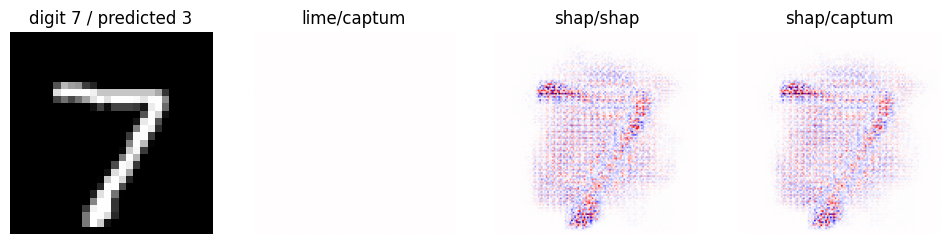

  [REVIEW] look at phase0_03_backend_maps.png: do the maps of both backends of each technique roughly highlight the digit? (meaningful only if check 6 ran first)
  -> check 3 status: FAIL (34.8s)

=== CHECK 4: Integrated Gradients (completeness, black baseline) ====================
  [PASS] baseline is black in the original image (max |denormalized| = 3.0e-08); in normalized space it is [-2.118, -2.036, -1.804], NOT zero
  [PASS] completeness holds: worst relative error 3.602% with 50 steps
  [PASS] attribution is exactly zero wherever the image equals the baseline (background): True
  [INFO] IG median 0.12s/img
  -> check 4 status: PASS (0.5s)

=== CHECK 7: LIME grid segmentation (visual) ====================
  figure saved: outputs/phase0/phase0_07_lime_grid.png


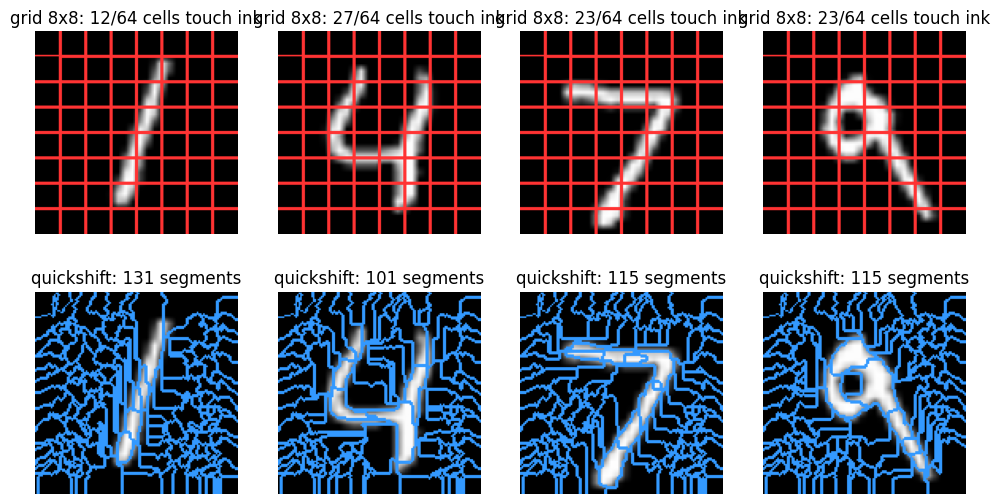

  [INFO] grid cells touching the digit (digits 1,4,7,9): [12, 27, 23, 23]
  [REVIEW] look at phase0_07_lime_grid.png: does the 8x8 grid separate the digit into a useful number of pieces (not 1-2 cells, not the whole image)? and is the quickshift row clearly worse (design D11 says so)? Confirm or change LIME_GRID_CELLS.
  -> check 7 status: REVIEW (1.1s)

=== CHECK 8: Digit mask (visual) ====================
  [INFO] thr=0.05,dil=0: mask covers 17.9% +/- 5.4% of the 784 pixels, empty masks: 0
  [INFO] thr=0.05,dil=1: mask covers 30.5% +/- 7.5% of the 784 pixels, empty masks: 0
  [INFO] thr=0.05,dil=2: mask covers 42.6% +/- 9.4% of the 784 pixels, empty masks: 0
  [INFO] thr=0.1,dil=0: mask covers 17.1% +/- 5.3% of the 784 pixels, empty masks: 0
  [INFO] thr=0.1,dil=1: mask covers 29.8% +/- 7.4% of the 784 pixels, empty masks: 0
  [INFO] thr=0.1,dil=2: mask covers 41.9% +/- 9.3% of the 784 pixels, empty masks: 0
  [INFO] thr=0.2,dil=0: mask covers 15.9% +/- 5.1% of the 784 pixels, empty 

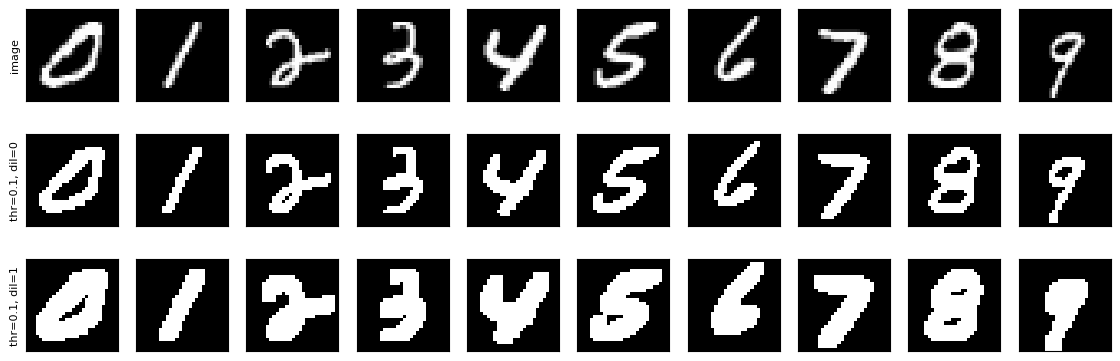

  [REVIEW] look at phase0_08_mask.png: does the dilated mask cover the whole stroke and its immediate halo without swallowing the background? Confirm MASK_THRESHOLD and MASK_DILATION. NOTE: dilation uses a 3x3 square element (8-connected), a detail the design did not specify (errata E17).
  -> check 8 status: REVIEW (1.4s)

=== CHECK 11: Occlusion behaviour (overlap, channels, forwards) ====================
  [INFO] overlapping windows are averaged (distinct values on the toy model: [768.0])
  [PASS] forward images used: 226 (windows expected: 225, +1 for the original image)
  [PASS] windows cover all 3 channels together: channel maps identical (max diff 0.0e+00) -> take the mean over channels
  [PASS] output shape (1, 3, 128, 128), finite
  [INFO] Occlusion 0.34s/img
  -> check 11 status: PASS (0.5s)

=== CHECK 12: Resampling rule to the 28x28 grid ====================
  [PASS] 28 -> 128 -> 28 round trip keeps every test pixel in place: 100/100
  [PASS] each 4x4 Grad-CAM cell peaks in

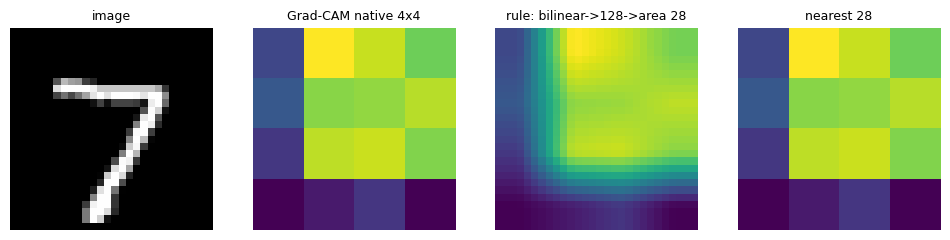

  [REVIEW] look at phase0_12_resampling.png: is the rule's 28x28 map a faithful, smooth version of the native Grad-CAM (and clearly better than blocky nearest)? Confirm the rule (errata E03).
  -> check 12 status: REVIEW (0.3s)

=== CHECK 9: Timings and N_QUANT ====================
  [INFO] seconds per image, all five techniques: 8.4 (LIME backend captum, SHAP backend shap)
  [PASS] N_QUANT = 100: quantitative stage ~14.1 min (budget 20 min)
  [PASS] 'Esegui tutto' with MODEL_MODE=load: ~21 min (limit 30 min)
  [PASS] 'Esegui tutto' with MODEL_MODE=train: ~22 min (limit 45 min)
  [INFO] breakdown: gallery 5.1 min, test inference 0.2 min, fixed overhead 2 min
  [WARN] quick run: these timings come from random weights and tiny data, NOT valid for decisions
  -> check 9 status: WARN (0.0s)

=== CHECK 10: Backend decision and table of fixed values ====================

| Parameter | Initial | Proposed | Basis | Confirmation |
|---|---|---|---|---|
| LIME_BACKEND | lime | captum | check 3 |

<Figure size 640x480 with 0 Axes>

In [ ]:
# avoid cloning inside an already-cloned folder
 %cd /content
!git clone https://github.com/francescofrigerio/profai_11_xai_prj_bancavirtuosa

# wherever config.py and this file live
%cd profai_11_xai_prj_bancavirtuosa/1_design/fase_0

!pip -q install captum lime shap scikit-image

# quick -> ~minutes, random weights, tiny data: catches script bugs
%run phase0_checks.py --quick
# %run phase0_checks.py



**GIT CLONE DAL REPOSITORY IN PRODUZIONE OPPURE MOUNT DRIVE IN SVILUPPO**

In [ ]:
def run_mount_drive(flag_mount=True):
   """
        Mount Drive for load dataset
   """

   if flag_mount :
      from google.colab import drive
      # drive.mount('/gdrive'
      drive.mount('/content/drive')
      #Colab Notebooks\ProfAi\Corso 09 Generative AI\ProjectCyberEyeSolution
      # %cd drive/MyDrive/'Colab Notebooks'/ProfAi/'Corso 11 ExplainedAi'/ProjectCyberEyeSolution/
      %cd drive/MyDrive/'Colab Notebooks'/ProfAi/'Corso 11 ExplainedAi'/ProjectBancaVirtuosaXai/

   else:
      %cd ProjectBancaVirtuosaXai/
   %ls

run_mount_drive(flag_mount=True)

Mounted at /content/drive
/content/drive/MyDrive/Colab Notebooks/ProfAi/Corso 11 ExplainedAi/ProjectBancaVirtuosaXai
checkpoint_fase_0.pt  data/


In [ ]:
# installazione pacchett
!pip -q install captum

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 455.2/455.2 kB 6.6 MB/s eta 0:00:00


In [ ]:
from tqdm.auto import tqdm
import logging

#DEBUG
# 1. Configurazione di base
# Qui decidiamo il livello minimo (WARNING) e il formato del messaggio
# nel codice con setTrace attivo il debug
logging.basicConfig(
    level=logging.WARNING,
    # level=logging.DEBUG,
    format='%(asctime)s - %(levelname)s - [%(funcName)s] - %(message)s',
    datefmt='%H:%M:%S',
    force=True
)

# Creazione di un oggetto logger
logger = logging.getLogger("AiAppLogger")
logger.setLevel(logging.INFO)


import torch
import torch.nn as nn
import torch.nn.functional as F

# Librera specifica di pytorch per la computer vision
import torchvision
from torch.utils.data import random_split, DataLoader
import torchvision.models as models

# Libreria specfica di pytorch per effettuare trasformazioni
# su tensori che rappresentano delle immagini.
import torchvision.datasets as datasets
import torchvision.transforms as transforms
from torch.utils.data import Subset
# usata per validare i nostri conti e
# calcolare parametri e dimensioni della rete
# from torchsummary import summary

# Non serve pandas perchè non andiamo a leggere
# il dataset da un csv
import matplotlib.pyplot as plt
import numpy as np
import os
import random


# Aggiunti rispetto al codice originale
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split


# Altrimenti con la LogisticRegression
# non si vede il warning relativo alla mancata convergenza dopo max_iter
# import warnings
# warnings.filterwarnings('ignore')
import warnings

# 1. Ignora i warning legati alla deprecazione di argomenti nei modelli
warnings.filterwarnings('ignore', category=UserWarning, message=".*pretrained.*")

# 2. Ignora i FutureWarning di librerie terze (es. Pandas o NumPy interni a Torchvision)
warnings.filterwarnings('ignore', category=FutureWarning)
print("Script avviato con warning filtrati in modo selettivo!")


from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
import seaborn as sns


import pandas as pd
from PIL import Image





Script avviato con warning filtrati in modo selettivo!


In [ ]:
# Modelli di Base Saliency e Occlusion
from captum.attr import Saliency, Occlusion
# Modelli Avanzati Integrtared Gradience
from captum.attr import IntegratedGradients

**1. CONFIGURAZIONE E COSTANTI**

**2. RIPRODUCIBILITA'**

**3. CONTROLLO RUNTIME TYPE**


In [ ]:
from dataclasses import dataclass


@dataclass(frozen=True)
class ConfigConstantsDefault:
    """Global config. Replaces magic numbers with descriptive names."""

    # Reproducibility and environment
    SEED: int = 42
    # "auto" -> cuda if available, else cpu (warn on cpu)
    DEVICE: str = "auto"

    # Data
    # MNIST 1x28x28 -
    IMAGE_SIZE: int = 28
    # DenseNet 3x128x12
    DENSENET_SIZE: int = 128
    NUM_CLASSES: int = 10
    # stratified split of the 60k train set
    VAL_SIZE: int = 6000
    # fixed validation images (one per class)
    NUM_DEBUG_IMAGES: int = 10

    # Model and training
    BACKBONE_WEIGHTS: str = "IMAGENET1K_V1"
    # True -> head only, BatchNorm of backbone in eval
    FREEZE_BACKBONE: bool = True
    # warning (not stop) if validation accuracy is below
    MIN_VAL_ACCURACY: float = 0.95
    NUM_EPOCHS: int = 5
    # to confirm in phase zero
    BATCH_SIZE: int = 64
    OPTIMIZER: str = "adam"
    # used when FREEZE_BACKBONE=True
    LEARNING_RATE_HEAD: float = 1e-3
    # used when FREEZE_BACKBONE=False
    LEARNING_RATE_FULL: float = 5e-5
    EARLY_STOPPING_PATIENCE: int = 2
    # "auto" | "train" | "load"
    MODEL_MODE: str = "auto"
    CHECKPOINT_PATH: str = "checkpoints/densenet121_mnist.pt"

    FLAG_BATCHNORM_EVAL: bool = True
    FLAG_RELU_INPLACE: bool = True

    # Grad-CAM
    GRADCAM_LAYER: str = "features.norm5"
    GRADCAM_ALT_LAYER: str = "features.denseblock3"   # for the comparison figure
    GRADCAM_DEBUG_EPOCHS: str = "first_last"

    # Logistic regression baseline
    LR_PENALTY: str = "l2"
    LR_SOLVER: str = "lbfgs"
    LR_C: float = 1.0
    # check ConvergenceWarning in phase zero
    LR_MAX_ITER: int = 1000
    USE_SURROGATE: bool = False # Obsolete

    # XAI techniques
    # "lime" | "captum"  (provisional, phase zero)
    LIME_BACKEND: str = "lime"
    # "shap" | "captum"  (provisional, phase zero)
    SHAP_BACKEND: str = "shap"
    IG_STEPS: int = 50
    OCCLUSION_WINDOW: int = 16
    OCCLUSION_STRIDE: int = 8
    LIME_NUM_SAMPLES: int = 1000
    # 8x8 grid segmentation (to check visually)
    LIME_GRID_CELLS: int = 8
    SHAP_NUM_BACKGROUND: int = 50

    # Sampling
    GALLERY_SIZE: int = 24
    # quantitative sample; fixed after timing in phase zero
    N_QUANT: int = 100

    # Comparison
     # Spearman and IoU
    COMPUTE_AGREEMENT: bool = True
    # "absolute" | "positive"
    SIGN_MODE: str = "absolute"
    # "digit" | "full"
    MASK_MODE: str = "digit"
    # intensity above which a pixel belongs to the digit
    MASK_THRESHOLD: float = 0.1
    MASK_DILATION: int = 1
    TOPK_FRACTION: float = 0.2
    # deletion curves
    COMPUTE_FAITHFULNESS: bool = False
    DELETION_STEPS: int = 10

    # Execution and outputs
    RUN_TESTS: bool = False
    OUTPUT_DIR: str = "outputs"

    def __post_init__(self):
        # Validate combinations that would otherwise fail late or silently
        if self.LR_PENALTY != "l2" and self.LR_SOLVER == "lbfgs":
            raise ValueError("lbfgs supports only the l2 penalty: use saga for l1/elasticnet")
        if self.MODEL_MODE not in ("auto", "train", "load"):
            raise ValueError("MODEL_MODE must be auto, train or load")
        if self.SIGN_MODE not in ("absolute", "positive"):
            raise ValueError("SIGN_MODE must be absolute or positive")
        if self.MASK_MODE not in ("digit", "full"):
            raise ValueError("MASK_MODE must be digit or full")


CONFIG = ConfigConstantsDefault()

# Random seed for reproducibility
# SEED = 42
SEED = CONFIG.SEED
# fissiamo la riproducibilità
# in tutte le librerie:random,environment,numpy,torch
random.seed(SEED)
os.environ['PYTHONHASHSEED'] = str(SEED)
np.random.seed(SEED)
# torch.manual_seed(0)
torch.manual_seed(SEED)

# BATCH_SIZE=32
BATCH_SIZE=CONFIG.BATCH_SIZE

print(torch.cuda.is_available())
# settiamo 'cuda' per la GPU altrimenti verra settata la 'cpu'
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(device)

True
cuda


### Modello
- DenseNet121 con pesi `IMAGENET1K_V1`; `classifier` sostituito da `Linear(1024, 10)`.
- **ReLU in-place:** i blocchi usano `ReLU(inplace=True)` e il `forward` finale usa `F.relu(..., inplace=True)` in forma funzionale. Questo rompe gli hook di Grad-CAM e il backward di Captum/SHAP. Va gestito (moduli a `inplace=False`; per il `forward` finale un wrapper sottile). **Da verificare in fase zero.**
- `FREEZE_BACKBONE=True`: `requires_grad=False` su `features`; l'ottimizzatore riceve solo i parametri del `classifier`; **le BatchNorm del backbone restano in `eval`**.

### Perché le BatchNorm in eval
`requires_grad=False` ferma l'aggiornamento dei **pesi**, ma non quello delle **statistiche** (`running_mean`, `running_var`) delle BatchNorm, che in modalità `train()` si aggiornano a ogni batch. MNIST è molto diverso da ImageNet (sfondo quasi tutto nero), quindi le statistiche si sposterebbero e le feature "congelate" cambierebbero senza che nessun peso sia stato modificato. `model.train()` rimette tutti i moduli in train, quindi il freeze va **riapplicato a ogni inizio di epoca** (anche dopo la validation).



**FUNCTION PLOT GRAPH AND IMAGES** <br>

In [ ]:
# funzione per convertire un'immagine da tensore ad un formato visualizzabile
def back_to_image_05(img):
    # DeNormalizzazione
    # faccio l'operazione inversa della normalizzazione
    # domanda su ProfAi
    img = img / 2 + 0.5
    # trasformo in un vettore numpy
    npimg = img.numpy()
    # print("npimg",type(npimg))
    # Facciamo una trasposta perchè , per poter essere
    # visualizzati i canali devono essere all'ultimo posto
    # Non avremo più un tensore ma una matrice numpy
    # avente shape 28x28x1

    # La funzione squeeze di NumPy viene utilizzata per rimuovere le dimensioni
    # di un array che hanno una dimensione pari a 1. In altre parole, "squeeze"
    # elimina le dimensioni singolari di un array, riducendo il numero di dimensioni
    # senza perdere dati.
    # return img.squeeze() # -> soluzione del tutor
    return np.transpose(npimg, (1, 2, 0)) # soluzione esercizio il risultato è lo stesso

def imshow_05(img):
    """
        Trasformazione inversa dell'immagine nello spazio dei colori.
        Faccio una trasposta nello spazio dei colori altrimenti
        l'immagine non avrà il colore corretto.
        la normalizzazione è diversa da quella sul dataset
        ma influisce solo sulla visualizzazione
    """
    img = img / 2 + 0.5     # unnormalize
    npimg = img.numpy()
    plt.imshow(np.transpose(npimg, (1, 2, 0)))
    plt.show()

def imshow(img):
    """
        Trasformazione inversa dell'immagine nello spazio dei colori.
        Faccio una trasposta nello spazio dei colori altrimenti
        l'immagine non avrà il colore corretto.
        la normalizzazione è diversa da quella sul dataset
        ma influisce solo sulla visualizzazione
    """

    # Definizione dei valori ImageNet per i 3 canali RGB
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    # img = img / 2 + 0.5     # unnormalize
    # print(f"type {type(img)} ")
    # print(f"img {img.shape} ")
    # img = (img * std) + mean # unnormalize
    # npimg = img.numpy()
    # plt.imshow(np.transpose(npimg, (1, 2, 0)))

    # Se il tensore è su GPU, lo portiamo su CPU prima di convertirlo in NumPy
    if isinstance(img, torch.Tensor):
        img = img.cpu().detach().numpy()

    # 1. Portiamo i canali alla fine: (C, H, W) -> (H, W, C)
    # Esempio: da (3, 128, 128) diventa (128, 128, 3)
    npimg = np.transpose(img, (1, 2, 0))
    # 2. Denormalizzazione corretta: x = (y * std) + mean
    # NumPy applica automaticamente l'operazione su ogni canale lungo l'ultimo asse
    npimg = (npimg * std) + mean
    plt.imshow(npimg)



    plt.show()


def back_to_image(img):
    # Definizione dei valori ImageNet per i 3 canali RGB
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])

    # Se il tensore è su GPU, lo portiamo su CPU prima di convertirlo in NumPy
    if isinstance(img, torch.Tensor):
        img = img.cpu().detach().numpy()

    # 1. Portiamo i canali alla fine: (C, H, W) -> (H, W, C)
    # Esempio: da (3, 128, 128) diventa (128, 128, 3)
    npimg = np.transpose(img, (1, 2, 0))

    # 2. Denormalizzazione corretta: x = (y * std) + mean
    # NumPy applica automaticamente l'operazione su ogni canale lungo l'ultimo asse
    npimg = (npimg * std) + mean

    # 3. Clip per evitare che imprecisioni nei float uscano dal range valido [0, 1] per matplotlib
    npimg = np.clip(npimg, 0, 1)

    return npimg


# Funzione per visualizzare la matrice di confusione
def plot_confusion_matrix_lr(model,X,y, title , str_train_test):
    """
         Plot Confusion Matrix Table
    """

    cm = confusion_matrix(y, model.predict(X))


    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.xlabel('Predicted ' + str_train_test)
    plt.ylabel('True ' + str_train_test)
    plt.title(title + str_train_test)









**FUNCTION LOAD AND PREPROCESSING DATASET** <br>


In [ ]:
def load_dataset_lr():

    transform_lr = transforms.Compose([ transforms.Grayscale(num_output_channels=1),
                                    # Converti in tensore
                                    transforms.ToTensor(),
                                  ])

    mnist_trainvalset_lr = datasets.MNIST(root='./data', train=True, download=True, transform=transform_lr)
    mnist_testset_lr = datasets.MNIST(root='./data', train=False, download=False, transform=transform_lr)

    return mnist_trainvalset_lr,mnist_testset_lr

def load_dataset_cnn():
    # Prendo immagini a caso e le visualizzo
    transform_densenet = transforms.Compose([ # Aumenta altezza e larghezza delle immagini
                                     transforms.Resize((128, 128)),
                                     # Converti in tensore
                                     transforms.ToTensor(),
                                    # espando i canali da 1 a 3
                                    transforms.Lambda(lambda x: x.repeat(3, 1, 1) if x.shape[0] == 1 else x), # Espande a 3 canali
                                    # normalizzazione delle img
                                    transforms.Normalize(
                                    mean=   [0.485, 0.456, 0.406],
                                    std=[0.229, 0.224, 0.225]
                                    )
                                    ])

    mnist_trainvalset_cnn = datasets.MNIST(root='./data', train=True, download=True, transform=transform_densenet)
    mnist_testset_cnn = datasets.MNIST(root='./data', train=False, download=False, transform=transform_densenet)

    return mnist_trainvalset_cnn,mnist_testset_cnn

def split_dataset(trainvalset ,train_size = 54000,val_size = 6000):


    # (Funziona per i dataset Torch standard come MNIST)
    targets = trainvalset.targets

    # Calcoliamo la frazione di validazione desiderata (es. 6000 su 54000 = ~11.1%)
    val_fraction = val_size / (train_size + val_size)

    # 2. Otteniamo gli indici stratificati per train e validation
    # stratify=targets: Dice a scikit-learn di mantenere la stessa identica percentuale di ogni classe (da '0' a '9') sia in train_indices che in val_indices.

    train_indices, val_indices = train_test_split( range(len(trainvalset)),
                                                    test_size=val_fraction,
                                                    # stratificazione!
                                                    stratify=targets,
                                                    random_state=SEED
                                                   )

    # 3. Creiamo i Subset di PyTorch usando gli indici stratificati
    train_dataset = Subset(trainvalset, train_indices)
    val_dataset = Subset(trainvalset, val_indices)

    return train_dataset,val_dataset


def load_dataloader_old_cnn(trainvalset,testset, train_size = 54000,val_size = 6000):
      """
           Caricamento del dataLoader
      """

      # Facendo così non avviene la stratificazione
      train_dataset, val_dataset = random_split( trainvalset,
                                                   [train_size, val_size],
                                                   # Seed per riproducibilità
                                                   generator=torch.Generator().manual_seed(SEED)  )

      trainval_loader = DataLoader(trainvalset, batch_size=len(mnist_trainvalset), shuffle=False)
      train_loader_cnn = DataLoader(train_dataset_cnn, batch_size=BATCH_SIZE,shuffle=True)
      test_loader_cnn = DataLoader(mnist_testset_cnn, batch_size=BATCH_SIZE,shuffle=False)

      return trainval_loader,train_loader_cnn,test_loader_cnn


def dataloader_to_tensor( dataloader_ , channels , w , h ):

    # Alloco i tensori 1, 28, 28
    # Dove sono allocati sulla GPU o la CPU ?
    X = torch.empty((len(dataloader_.dataset),  channels , w , h),
                dtype=torch.float32)
    y = torch.empty((len(dataloader_.dataset),),
                dtype=torch.int64)

    start = 0
    for images, labels in dataloader_:
        # images ha forma (64, 3, 128, 128) -> il tuo X
        # labels ha forma (64,)             -> il tuo y
        n = images.size(0)

        X[start:start+n].copy_(images)
        y[start:start+n].copy_(labels)

        start += n

    print(" X " , X.shape)
    print(" y " , y.shape)
    return X , y

def get_images_labels(dataset_,flag_data_loader=True,idx_dataset=0):

    if flag_data_loader:
        # sola volta in tutto il codice
        dataloader = DataLoader(dataset_, batch_size=32, shuffle=True)
        print(len(dataset_), "immagini,", len(dataset_.class_to_idx), "identità")
        dataiter = iter(dataloader)
        # i valori di images e labels sono tensori di pytorch
        images_, labels_ = next(dataiter)
    else:
        image, label = dataset_[idx_dataset]
        # images_ = [image]
        # labels_ = [label]
        # torch.stack() prende in input una lista di tensori e li impila lungo una nuova dimensione.
        images_ = torch.stack([image])
        # costruisce un nuovo tensore a partire da un valore (o lista di valori) Python nativi
        labels_ = torch.tensor([label])
    return images_, labels_


**FUNZIONE SPECIFICHE PER LA REGRESSIONE LOGISTICA**

In [ ]:
def run_train_lr(max_iter_=100):
    """
        Train Regressione Logistica
    """
    trainval_dataset_lr , test_dataset_lr = load_dataset_lr()
    train_size = len(trainval_dataset_lr) - CONFIG.VAL_SIZE
    val_size = CONFIG.VAL_SIZE

    logger.info(f" train_size {train_size}")
    logger.info(f" val_size {val_size}")

    train_dataset_lr , val_dataset_lr = split_dataset(trainval_dataset_lr ,train_size = train_size,val_size = val_size)

    train_loader_lr = DataLoader(trainval_dataset_lr, batch_size=BATCH_SIZE,shuffle=True)
    test_loader_lr = DataLoader(test_dataset_lr, batch_size=BATCH_SIZE,shuffle=False)

    # Carico i tensori di train e test
    X_train , y_train = dataloader_to_tensor(train_loader_lr,1, CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE)
    X_test , y_test = dataloader_to_tensor(test_loader_lr,1, CONFIG.IMAGE_SIZE, CONFIG.IMAGE_SIZE)

    # appiattisco i tensori
    X_train = X_train.reshape(X_train.shape[0], -1)
    X_test = X_test.reshape(X_test.shape[0], -1)

    logger.info(f" X_train flat {X_train.shape}")
    logger.info(f" X_test flat {X_test.shape}")

    # Converto il tensore nel formato numpy preferito da LogisticRegression
    X_train = X_train.numpy()
    X_test = X_test.numpy()

    logger.info(f" X_train numpy {X_train.shape}")
    logger.info(f" X_test numpy {X_test.shape}")

    lr = LogisticRegression( random_state=SEED,max_iter=max_iter_).fit(X_train,y_train)

    # Calcolo dell'accuratezza di addestramento e test per la Logistic Regression
    test_accuracy_lr = accuracy_score(y_test, lr.predict(X_test))
    print(f"Accuratezza di test (Logistic Regression): {test_accuracy_lr}")

    # stampo solo la confusion matrix sul test
    # plot_confusion_matrix(lr,X_train,y_train, "CLASSIFIER LR ON MNIST DATASET " , "TRAIN")
    plot_confusion_matrix_lr(lr,X_test,y_test, "CLASSIFIER LR ON MNIST DATASET " , "TEST")

**FUNZIONE SPECIFICHE PER LA CNN**

In [ ]:
# Funzione per visualizzare la matrice di confusione
def plot_confusion_matrix_cnn(y_true_,y_pred_, title , str_train_test):
    """
         Plot Confusion Matrix Table
    """

    cm = confusion_matrix(y_true_, y_pred_)

    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False)
    plt.xlabel('Predicted ' + str_train_test)
    plt.ylabel('True ' + str_train_test)
    plt.title(title + str_train_test)

def set_batchnorm_eval(module: nn.Module) -> None:
    """Keep BatchNorm running statistics frozen (specification of the design)."""
    if isinstance(module, nn.modules.batchnorm._BatchNorm):
        module.eval()


def enter_train_mode(model: nn.Module, config) -> None:
    """Single entry point to put the model in training mode. Call at the start of EVERY epoch."""
    model.train()
    if config.FREEZE_BACKBONE and CONFIG.FLAG_BATCHNORM_EVAL:
        model.features.apply(set_batchnorm_eval)


def set_relu_inplace(module):
    """
         Apply modify to input model
         set_relu_inplace(model)
    """
    for name, child in module.named_children():
        if isinstance(child, nn.ReLU):
            # Sostituisce il layer ReLU esistente con uno in-place
            setattr(module, name, nn.ReLU(inplace=True))
        else:
            # Scende nei sottoblocchi (es. nei DenseBlock di DenseNet)
            set_relu_inplace(child)


def run_train_cnn(model_ ,
                  dataset_,
                  dataloader_train_ ,
                  dataloader_val_ ,
                  device_ ,
                  optimizer_ ,
                  criterion_ ,
                  num_epochs_=1):

    model_ = model_.to(device_)

    # Training loop
    for epoch in range(num_epochs_):
        # model_.train()
        enter_train_mode(model_,CONFIG)
        running_loss = 0.0
        for i, (inputs, labels) in enumerate(dataloader_train_):
            inputs, labels = inputs.to(device_), labels.to(device_)

            optimizer_.zero_grad()
            outputs = model_(inputs)
            loss = criterion_(outputs, labels)
            loss.backward()
            optimizer_.step()

            running_loss += loss.item()
            if i % 1000 == 900:    # stampa ogni 100 mini-batch
                logger.info(f'[Epoca {epoch + 1}, Ciclo {i + 1:5d}] Loss: {running_loss / 10:.3f}')
                running_loss = 0.0
                # break

        # CICLO VALIDATION
        y_pred,y_true,y_pred_desc,y_true_desc = run_test_cnn(model_,
                                                             dataset_,
                                                             dataloader_val_,
                                                             device_)
        val_accuracy_cnn = accuracy_score(y_true,y_pred)
        if ( val_accuracy_cnn < CONFIG.MIN_VAL_ACCURACY ):
            logger.info(f"ATTENZIONE!! Accuratezza(DenseNet Cnn) Non Supera la Soglia({CONFIG.MIN_VAL_ACCURACY}): {val_accuracy_cnn}")



    logger.info('Train completato')

def run_test_cnn(model_ ,
                dataset_,
                dataloader_ ,
                device_ ):


    model_ = model_.to(device_)

    model_.eval()
    y_pred_=[]
    y_true_=[]

    y_pred_desc_=[]
    y_true_desc_=[]
    with torch.no_grad():
        for i, (images, labels) in enumerate(dataloader_):
            images, labels = images.to(device_), labels.to(device_)

            # print images gid with relative prevision and ground truth

            # prendo l'output delle previsioni direttamente
            # dalle immagini caricate applicando la nostra rete neurale convolutiva
            # e addestrata .
            outputs_ = model_(images)
            # Ottengo il valore della classe prevista
            # usando le etichette per gli output ottenuti che abbiamo definito come prima.
            _, predicted = torch.max(outputs_, 1)

            y_true_.append(labels)
            y_pred_.append(predicted)

            # print("y_true",y_true.shape)
            # print("y_pred",y_pred.shape)
            # y_true (10000,)
            # y_pred (10000,)

            y_pred_desc_.append(dataset_.classes[lbl] for lbl in predicted.cpu())
            # senza convertire numpy avrei una lista di tensori
            # y_pred_ = [ tensor([...64 predizioni...]), tensor([...64 predizioni...]), ... ]
            y_true_desc_.append(dataset_.classes[lbl] for lbl in labels.cpu())



    y_true_ = torch.cat(y_true_).cpu().numpy()
    y_pred_ = torch.cat(y_pred_).cpu().numpy()

    return y_pred_,y_true_,y_pred_desc_,y_true_desc_



def run_predict_on_image(dataset_,images_,labels_):

    images_, labels_ = images_.to(device), labels_.to(device)
    # print images gid with relative prevision and ground truth
    imshow(torchvision.utils.make_grid(images_.cpu().detach()))

    # prendo l'output delle previsioni direttamente
    # dalle immagini caricate applicando la nostra rete neurale convolutiva
    # e addestrata .
    outputs_ = model(images_)
    # Ottengo il valore della classe prevista
    # usando le etichette per gli output ottenuti che abbiamo definito come prima.
    _, predicted_ = torch.max(outputs_, 1)

    gt_pred_desc_ = [dataset_.classes[lbl] for lbl in predicted_]
    # logger.info(f"gt_pred_desc_ {gt_pred_desc_}")

    gt_label_desc_ = [dataset_.classes[lbl] for lbl in labels_]
    # logger.info(f"gt_label_desc {gt_label_desc}")
    # logger.info(f"labels len {len(labels)}")
    # logger.info(f"predicted len {len(predicted)}")
    #                               for j in range(4)))

    df_ = pd.DataFrame({"Ground Truth": gt_label_desc_, "Prediction": gt_pred_desc_})
    return df_ , gt_pred_desc_ , gt_label_desc_ , predicted_
    # 3. (Opzionale) Visualizza il DataFrame nel log o a schermo
    # logger.info(f"\n{df.head()}")


def run_main_cnn(num_epochs_=5):

    trainval_dataset_cnn , test_dataset_cnn = load_dataset_cnn()

    train_size = len(trainval_dataset_cnn) - CONFIG.VAL_SIZE
    val_size = CONFIG.VAL_SIZE

    train_dataset_cnn , val_dataset_cnn = split_dataset(trainval_dataset_cnn ,train_size = train_size,val_size = val_size)

    train_loader_cnn = DataLoader(train_dataset_cnn, batch_size=BATCH_SIZE,shuffle=True)
    val_loader_cnn = DataLoader(val_dataset_cnn, batch_size=BATCH_SIZE,shuffle=False)
    test_loader_cnn = DataLoader(test_dataset_cnn, batch_size=BATCH_SIZE,shuffle=False)

    # model = torch.hub.load('pytorch/vision:v0.10.0', 'densenet121', pretrained=True)
    # codice standard non scarica da github
    model = models.densenet121(weights=models.DenseNet121_Weights.DEFAULT)

    # permette di risparmiare memoria VRAM
    set_batchnorm_eval(model)

    for param in model.parameters():
        param.requires_grad = False

    # Modifichiamo l'ultimo layer per il numero corretto di classi
    num_classes = len(trainval_dataset_cnn.class_to_idx)
    # num_classes = len(mnist_trainvalset_cnn.classes)
    logger.info(f"num_classes {num_classes}")

    num_ftrs = model.classifier.in_features
    model.classifier = nn.Linear(num_ftrs, num_classes)

    # Controlli sui parametri
    total_params = sum(p.numel() for p in model.parameters())

    trainable_params = sum(p.numel() for p in model.parameters()
        if p.requires_grad)

    logger.info(f"Parametri totali: {total_params:,}")
    logger.info(f"Parametri congelati: {total_params - trainable_params:,}")
    logger.info(f"Parametri addestrabili: {trainable_params:,}")
    for name, param in model.named_parameters():
        if param.requires_grad:
            logger.info(f"{name} , {param.shape}")

    loss_function = nn.CrossEntropyLoss()
    # Setto optimzers lo stocastic gradient descend
    # un learning rate=0.05
    # il parametro momentum=0.09
    # optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
    optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    run_train_cnn(model_=model,
                  dataset_=val_dataset_cnn,
                  dataloader_train_=train_loader_cnn,
                  dataloader_val_=val_loader_cnn,
                  device_=device,
                  optimizer_=optimizer,
                  criterion_=loss_function,
                  num_epochs_=num_epochs_)

    y_pred, y_true, y_pred_desc, y_true_desc = run_test_cnn(model,test_dataset_cnn,test_loader_cnn,device)

    test_accuracy_cnn = accuracy_score(y_true,y_pred)
    logger.info(f"Accuratezza di test (DenseNet Cnn): {test_accuracy_cnn}")
    plot_confusion_matrix_cnn(y_true,y_pred, "CLASSIFIER LR ON MNIST DATASET " , "TEST")

    return model,optimizer,loss_function

def run_predict_on_image(dataset_,images_,labels_):

    images_, labels_ = images_.to(device), labels_.to(device)
    # print images gid with relative prevision and ground truth
    imshow(torchvision.utils.make_grid(images_.cpu().detach()))

    # prendo l'output delle previsioni direttamente
    # dalle immagini caricate applicando la nostra rete neurale convolutiva
    # e addestrata .
    outputs_ = model(images_)
    # Ottengo il valore della classe prevista
    # usando le etichette per gli output ottenuti che abbiamo definito come prima.
    _, predicted_ = torch.max(outputs_, 1)

    gt_pred_desc_ = [dataset_.classes[lbl] for lbl in predicted_]
    # logger.info(f"gt_pred_desc_ {gt_pred_desc_}")

    gt_label_desc_ = [dataset_.classes[lbl] for lbl in labels_]
    # logger.info(f"gt_label_desc {gt_label_desc}")
    # logger.info(f"labels len {len(labels)}")
    # logger.info(f"predicted len {len(predicted)}")
    #                               for j in range(4)))

    df_ = pd.DataFrame({"Ground Truth": gt_label_desc_, "Prediction": gt_pred_desc_})
    return df_ , gt_pred_desc_ , gt_label_desc_ , predicted_
    # 3. (Opzionale) Visualizza il DataFrame nel log o a schermo
    # logger.info(f"\n{df.head()}")









**CARICO IL DATASET MNIST** <br>
[accedi a GitHub](https://git-disl.github.io/GTDLBench/datasets/mnist_datasets/)

[Dataset su torch](https://docs.pytorch.org/vision/stable/datasets.html) <br>
[Dataset MNIST su torch](https://docs.pytorch.org/vision/stable/generated/torchvision.datasets.MNIST.html#torchvision.datasets.MNIST)

In [ ]:
transform = transforms.Compose([
    # transforms.Resize((28, 28)),   # Ridimensiona a 28x28
    # transforms.Grayscale(num_output_channels=1),  # Scala di grigi
    # Converti in tensore
    transforms.ToTensor(),
    # normalizzazione delle img anche se ottengo 99% accuracy senza di essa!!
    # mnist ha un solo canale per cui serve normalizzare
    # un solo canale
    # Quando le immagini sono rgb bisogna normalizzare tutti i canali
    # Media (mean): [0.485, 0.456, 0.406]
    # Deviazione Standard (std): [0.229, 0.224, 0.225]
    # transforms.Normalize((0.5),(0.5))
    transforms.Normalize( mean=[(0.485+0.456+0.406)/3],
                          std=[(0.229+0.224+0.225)/3]) ])



In [ ]:
# i dati sono già normalizzati per cui posso anche mettere a None il param transform
# mnist_trainvalset = datasets.MNIST(root='./data', train=True, download=True, transform=None)
# mnist_testset = datasets.MNIST(root='./data', train=False, download=False, transform=None)
# Uso il transform per convertire ogni elemento in un immagine 28x28x1
mnist_trainvalset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
mnist_testset = datasets.MNIST(root='./data', train=False, download=False, transform=transform)
print(len(mnist_trainvalset))
print(len(mnist_testset))





100%|██████████| 9.91M/9.91M [00:00<00:00, 132MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 29.0MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 108MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 11.8MB/s]


60000
10000


**ESPLORO IL DATASET**

In [ ]:

# Accedi al primo elemento del dataset
image, label = mnist_trainvalset[0]

# Stampa la dimensione dell'immagine e la label
print(image.shape)  # torch.Size([1, 28, 28])
print(label)        # Etichetta, ad esempio 5

torch.Size([1, 28, 28])
5


In [ ]:
# Così evidenzio solo l'immagine
# mnist_trainvalset[0][0]

print(mnist_trainvalset[0][0].shape) # shape dell'immagine
print(type(mnist_trainvalset[0])) # tupla [image,label]

print(mnist_trainvalset[0][0],"image") # tensor image 1x28x28
print(mnist_trainvalset[0][1],"label") # label
print(type(mnist_trainvalset[0][1]),"label type") # label

# Per vedere l'etichetta
# bisogna specificare tutto il primo tensore etichetta+label
# in fondo si vede la label=5
# mnist_trainvalset[0]

torch.Size([1, 28, 28])
<class 'tuple'>
tensor([[[-1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867],
         [-1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867],
         [-1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
          -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867],
         [-1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867, -1.9867,
        

In [ ]:
transform = transforms.Compose([
    # Aumenta la dimensione prima di aumentare i canali
    # e lavorando direttamente sull'immagine PIl.Image del mnist
    # Gli algoritmi di interpolazione su immagini PIL
    # sono ottimizzati per evitare artefatti visivi.
    transforms.Resize((128, 128)),
    # Converti in tensore
    transforms.ToTensor(),
    # espando i canalu da 1x28x28 a 3x28x28
    transforms.Lambda(lambda x: x.repeat(3, 1, 1) if x.shape[0] == 1 else x), # Espande a 3 canali
    # normalizzazione delle img
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
     ])

# Uso il transform per convertire ogni elemento in un immagine 28x28x1
mnist_trainvalset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
mnist_testset = datasets.MNIST(root='./data', train=False, download=False, transform=transform)

train_size = 54000
val_size = 6000

# Usiamo generator per fissare la seed e rendere la separazione riproducibile
train_dataset, val_dataset = random_split(
    mnist_trainvalset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(seed)  # Seed per riproducibilità
)


print("Full Train Val",len(mnist_trainvalset))
print("Test",len(mnist_testset))
print("Train",len(train_dataset))
print("Val",len(val_dataset))

Full Train Val 60000
Test 10000
Train 54000
Val 6000


normalized_image [[[-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  ...
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]]

 [[-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  ...
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]]

 [[-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  ...
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]]

 ...

 [[-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  ...
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 -1.80444443]
  [-2.11790393 -2.03571415 

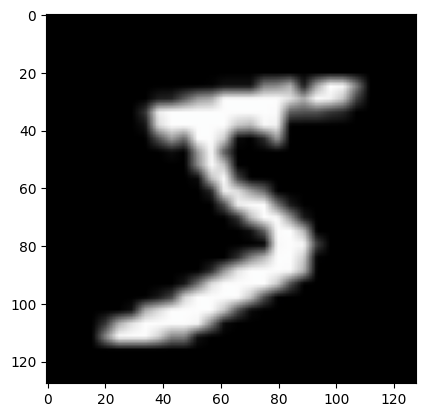

In [ ]:

image = back_to_image(mnist_trainvalset[0][0])

mean = np.array([0.485, 0.456, 0.406])
std = np.array([0.229, 0.224, 0.225])

normalized_image = (image - mean) / std
print("normalized_image",normalized_image)

print(image.shape)
# metto cmap=gray perchè abbiamo un solo canale
plt.imshow(image,cmap='gray')

plt.show()

(128, 128, 3)


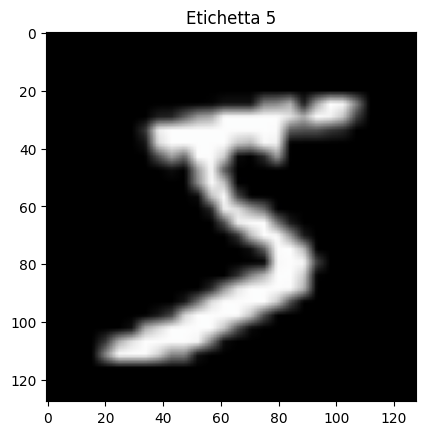

In [ ]:
# Posso fare una funzione
image, label = mnist_trainvalset[0]

image = back_to_image(image)
print(image.shape)
plt.imshow(image,cmap='gray')
plt.title("Etichetta "+str(label))
plt.show()

In [ ]:
classes_label=['0','1','2','3','4','5','6','7','8','9']
labels_all = []
for _, label in mnist_trainvalset:
    labels_all.append(label)

# labels_array = np.array(labels).unique()
# labels_array
labels = set(labels_all)
labels

{0, 1, 2, 3, 4, 5, 6, 7, 8, 9}

**A cosa serve tight_layout() di Matplotlib** <br>
La funzione tight_layout di Matplotlib è utilizzata per ottimizzare automaticamente il layout delle figure. Spesso, quando si creano plot con Matplotlib, gli elementi del grafico (come etichette degli assi, titoli, e tick labels) possono sovrapporsi o essere tagliati, specialmente in figure con più subplot. tight_layout cerca di ridurre queste sovrapposizioni e di migliorare la leggibilità del grafico.

Ecco come funziona tight_layout:

Regolazione automatica: tight_layout calcola automaticamente le spaziature tra i subplot e i bordi della figura per garantire che tutti gli elementi siano visibili e non sovrapposti.
Esecuzione semplice: Si usa solitamente alla fine della creazione di una figura, prima di visualizzarla con plt.show(). Basta chiamare plt.tight_layout() senza parametri per ottenere un miglioramento del layout.
Parametri opzionali: Anche se può essere utilizzata senza parametri, tight_layout accetta diversi argomenti per personalizzare ulteriormente il layout, come pad (spazio aggiuntivo tra i subplot), w_pad e h_pad (spaziature orizzontali e verticali, rispettivamente), e rect (una lista che specifica la posizione della figura).

In [ ]:
iteration = 0

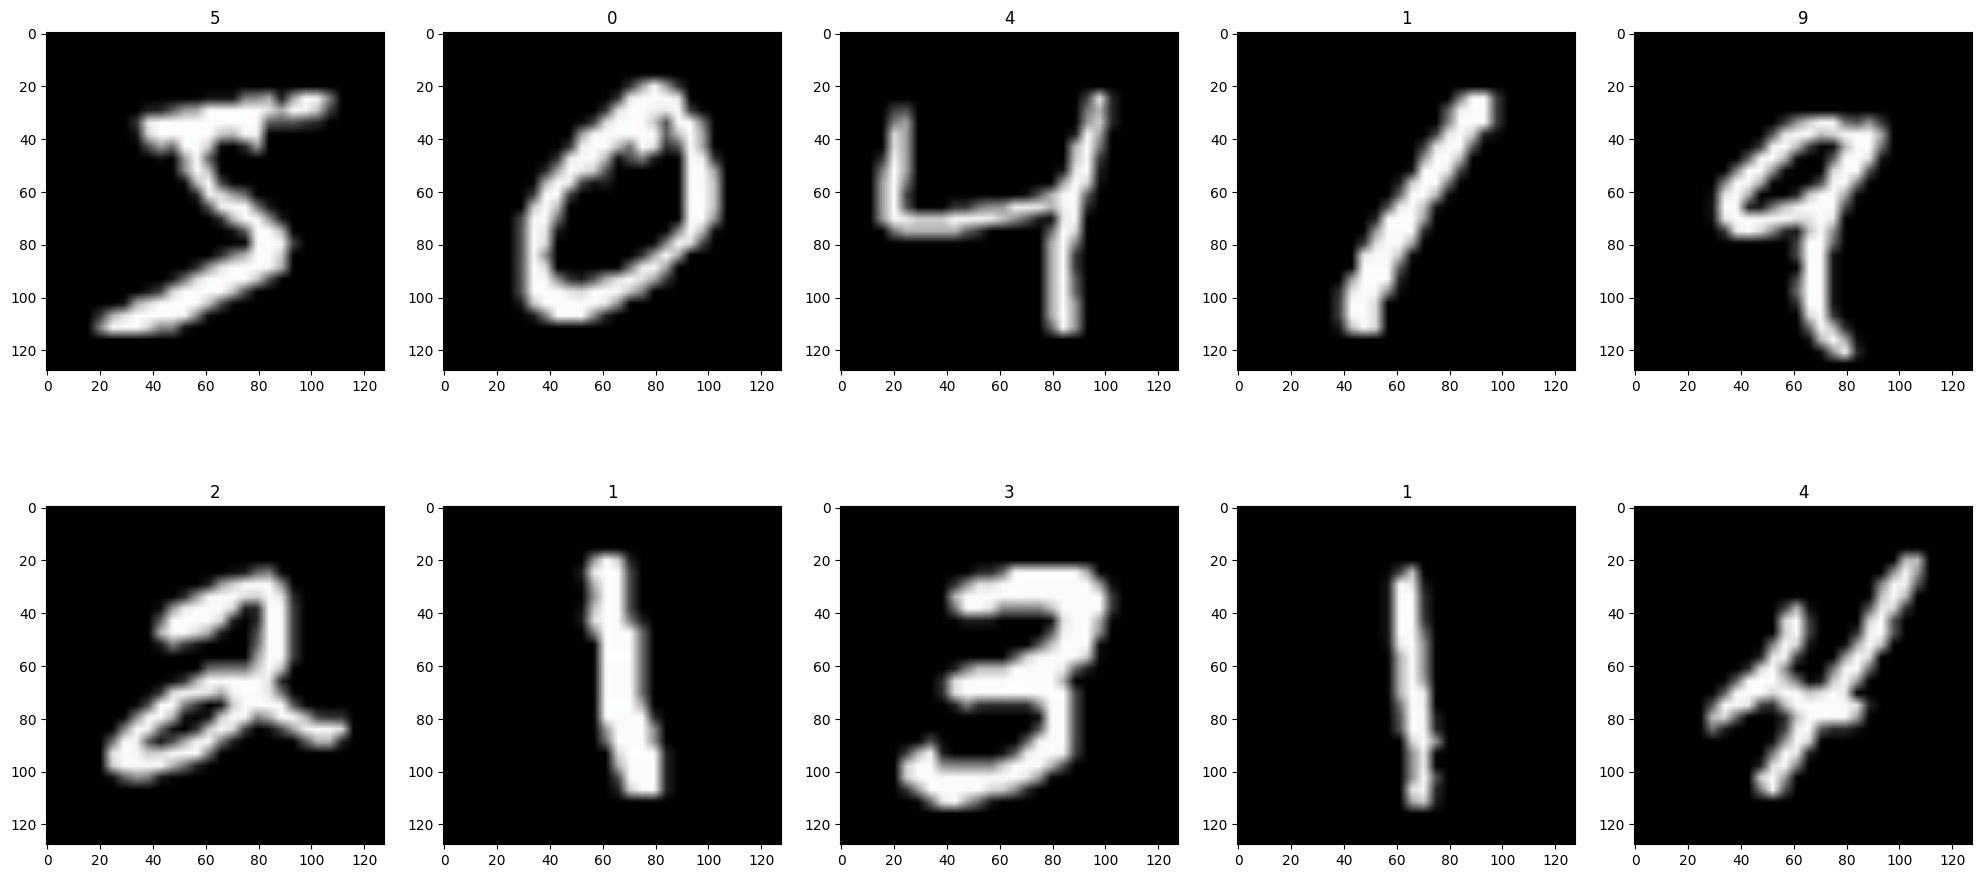

In [ ]:
# Visualizzo 10 numeri alla volta per ripartire da capo
# bisogna reinizializzare la variabile iteration
# Inspect the data
# Visualizzo le immagini in una griglia 2x5
# quindi 10 immagini su 2 righe e 5 colonne
num_row = 2
num_col = 5
# Per ogni griglia 2x5 stampo un subplots della singola immagine
# con la sua figsize 20x10
fig, axes = plt.subplots(num_row, num_col, figsize=(10*num_row,2*num_col))
# itero da 0 a 9 quindi stampo 10 elementi alla volta
# alla prima esecuzione carico le immagini da 0 a 9
# ma alla seconda grazie alla variabile iteration
# visualizzo da 10 a 19 e così via.
for i in range(num_row*num_col):
    # seleziono l'asse prendendo il resto e la
    # divisione con numero assoluto(non chiaro!!)
    # e' un modo semplice per iterare prima su riga poi su colonna
    ax = axes[i//num_col, i%num_col]
    ax.imshow(back_to_image(mnist_trainvalset[iteration * num_row * num_col + i][0]),cmap='gray')
    # Visualizzo la classe che corrisponde all'immagine
    ax.set_title('{}'.format(int(mnist_trainvalset[iteration * num_row * num_col + i][1])))
plt.tight_layout() #
plt.show()
# Eseguendo più volte il codice carico
# sempre nuove immagini
iteration += 1

**BASELINE REGRESSIONE LOGISTICA** <br>
Lascio la versione bacata perchè è un buon esempio di un cattivo codice in python e del ragionamento richiesto per arrivare a scrivere un buon codice.

**VERSIONE KO RIMANE COME INSEGNAMENTO**

In [ ]:
def dataloader_to_tensor_ko(my_dataloade):
    X_list = []
    y_list = []
    for images, labels in my_dataloade:
        # images ha forma (64, 3, 128, 128) -> il tuo X
        # labels ha forma (64,)             -> il tuo y
        # print(images.shape, labels.shap
        X_list.append(images)
        y_list.append(labels)

    # Concatenazione finale in un singolo Tensore PyTorch
    X = torch.cat(X_list, dim=0)
    y = torch.cat(y_list, dim=0)

    # Se i tuoi modelli richiedono array NumPy appiattiti (es. per Scikit-Learn):
    # X_np = X.view(X_train.size(0), -1).numpy()
    # y_np = y.numpy()
    return X , y

flag_run_bad_code=False

if flag_run_bad_code:

    transform = transforms.Compose([ # Aumenta altezza e larghezza delle immagini
                                     transforms.Resize((128, 128)),
                                     # Converti in tensore
                                     transforms.ToTensor(),
                                    # espando i canali da 1 a 3
                                    transforms.Lambda(lambda x: x.repeat(3, 1, 1) if x.shape[0] == 1 else x), # Espande a 3 canali
                                    # normalizzazione delle img
                                    transforms.Normalize(
                                    mean=   [0.485, 0.456, 0.406],
                                    std=[0.229, 0.224, 0.225]
                                    )
                                    ])

    # Uso il transform per convertire ogni elemento in un immagine 3x128x128
    mnist_trainvalset = datasets.MNIST(root='./data', train=True, download=True, transform=transform)
    mnist_testset = datasets.MNIST(root='./data', train=False, download=False, transform=transform)

    # mettere nella parametrizzazione
    train_size = 54000
    val_size = 6000

    # Usiamo generator per fissare la seed e rendere la separazione riproducibile
    train_dataset, val_dataset = random_split( mnist_trainvalset,
                                              [train_size, val_size],
                                               generator=torch.Generator().manual_seed(SEED)  # Seed per riproducibilità
                                      )

    images_labels = mnist_trainvalset
    # images_labels = train_dataset

    print("START TRAIN DATALOADER")
    # trainval_loader = DataLoader(mnist_trainvalset, batch_size=len(mnist_trainvalset), shuffle=False)
    train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE,shuffle=True)
    print("END TRAIN DATALOADER")
    print("START TEST DATALOADER")
    test_loader = DataLoader(mnist_testset, batch_size=BATCH_SIZE,shuffle=False)
    print("END TEST DATALOADER")

    print("START TRAIN DATALOADER TO TENSOR")
    X_train , y_train = dataloader_to_tensor(train_loader)
    print("START TEST DATALOADER TO TENSOR")
    X_test , y_test = dataloader_to_tensor_ko(test_loader)

    print("Shape X_train:", X_train.shape)  # torch.Size([54000, 3, 128, 128])
    print("Shape y_train:", y_train.shape)  # torch.Size([54000])


    # Estrazione immediata e vettorizzata di tutti gli X e y
    # X_train, y_train = next(iter(trainval_loader))
    # X_test, y_test = next(iter(test_loader))

    print(X_train.shape)  # torch.Size([54000, 3, 128, 128])
    print(y_train.shape)  # torch.Size([54000])
    print(X_test.shape)  # torch.Size([54000, 3, 128, 128])
    print(y_test.shape)  # torch.Size([54000])

    lr = LogisticRegression( random_state=seed).fit(X_train,y_train)

    # Calcolo dell'accuratezza di addestramento e test per la Logistic Regression
    test_accuracy_lr = accuracy_score(y_test, lr.predict(X_test))
    print(f"Accuratezza di test (Logistic Regression): {test_accuracy_lr}")

    plot_confusion_matrix_lr(lr, X_train , y_train , X_test , y_test, "CLASSIFIER LR ON MNIST DATASET" )





**BASELINE REGRESSIONE LOGISTICA** <br>

LogisticRegression di scikit-learn si aspetta normalmente una matrice bidimensionale: (numero_campioni, numero_feature). <br>
Quindi, prima ancora di discutere la RAM,
dobbiamo capire che cosa rappresenta ogni campione per il classificatore. <br>

Un'immagine RGB di dimensione 128×128 contiene tre canali. Volendo utilizzare ogni valore dei pixel come feature, quante feature avrà una singola immagine dopo averla appiattita? <br>
Un'immagine RGB di dimensione 128×128 contiene tre canali. Volendo utilizzare ogni valore dei pixel come feature, quante feature avrà una singola immagine dopo averla appiattita?  <br>
3x128x128=49152 perche le feature sono replicate sui tre canali quindi 49152  <br>


Ti propongo di ragionare su tre livelli: <br>

Attenzione alla RAM: il percorso a 28×28 riduce notevolmente la memoria rispetto a 128×128,
ma Logistic Regression può comunque richiedere memoria aggiuntiva durante l'addestramento.  <br>
Se necessario, valutare anche solver, regolarizzazione e una rappresentazione ancora più compatta. <br>

Il punto fondamentale è che possiamo mantenere le immagini a tre canali e 128×128 per DenseNet121,
usando una rappresentazione separata e più leggera per Logistic Regression.<br>


Dato originale: tensore PyTorch con quattro dimensioni. BATCH, CANALI , H , W <br>
Dato appiattito: matrice con 54.000 righe e 49.152 colonne. <br>
Modello: LogisticRegression, che durante il fit può richiedere
ulteriore memoria per le sue elaborazioni. <br>
l numero di elementi è: 54000x49152x4 byte ogni elemento un numero molto alto <br>

la matrice X_train in input al metodo fit
contiene circa  54000x49152=2,65 miliardi di valori.  <br>
Ma questo significa che la memoria necessaria è molto maggiore di quanto possa sembrare inizialmente. <br>

MNIST originale 1x28x28 = 784 <br>
MNIST modificato 3x128x128 = 49152 <br>

Posso utilizzare due diversi transform uno per il DenseNet e uno per per LogisticRegression rappresentando le immagini con 28x28 per LR e lasciare 3x128x128 solo per DenseNet


**VECCHIA VERSIONE OK**

100%|██████████| 9.91M/9.91M [00:00<00:00, 61.7MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 1.73MB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 15.1MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.2MB/s]


START TRAIN DATALOADER
END TRAIN DATALOADER
START TEST DATALOADER
END TEST DATALOADER
 X  torch.Size([54000, 1, 28, 28])
 y  torch.Size([54000])
 X  torch.Size([10000, 1, 28, 28])
 y  torch.Size([10000])
 X_train flat  torch.Size([54000, 784])
 X_test flat  torch.Size([10000, 784])
 X_train numpy  (54000, 784)
 X_test numpy  (10000, 784)
Accuratezza di test (Logistic Regression): 0.9269


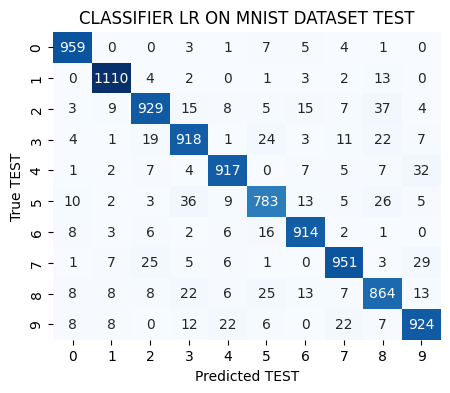

In [ ]:

transform_lr = transforms.Compose([ transforms.Grayscale(num_output_channels=1),
                                    # Converti in tensore
                                    transforms.ToTensor(),
                                  ])


# Uso il transform per convertire ogni elemento in un immagine 3x128x128
mnist_trainvalset_lr = datasets.MNIST(root='./data', train=True, download=True, transform=transform_lr)
mnist_testset_lr = datasets.MNIST(root='./data', train=False, download=False, transform=transform_lr)


# mettere nella parametrizzazione
train_size = 54000
val_size = 6000

# Usiamo generator per fissare la seed e rendere la separazione riproducibile
train_dataset_lr, val_dataset_lr = random_split( mnist_trainvalset_lr,
                                              [train_size, val_size],
                                               generator=torch.Generator().manual_seed(SEED)  # Seed per riproducibilità
                                      )

#images_labels = mnist_trainvalset_lr
# images_labels = train_dataset

print("START TRAIN DATALOADER")
# trainval_loader = DataLoader(mnist_trainvalset, batch_size=len(mnist_trainvalset), shuffle=False)
train_loader_lr = DataLoader(train_dataset_lr, batch_size=BATCH_SIZE,shuffle=True)
print("END TRAIN DATALOADER")
print("START TEST DATALOADER")
test_loader_lr = DataLoader(mnist_testset_lr, batch_size=BATCH_SIZE,shuffle=False)
print("END TEST DATALOADER")

# Carico i tensori di train e test
X_train , y_train = dataloader_to_tensor(train_loader_lr,1, 28, 28)
X_test , y_test = dataloader_to_tensor(test_loader_lr,1, 28, 28)

# appiattisco i tensori
X_train = X_train.reshape(X_train.shape[0], -1)
X_test = X_test.reshape(X_test.shape[0], -1)

print(" X_train flat " , X_train.shape)
print(" X_test flat " , X_test.shape)

# Converto il tensore nel formato numpy preferito da LogisticRegression
X_train = X_train.numpy()
X_test = X_test.numpy()


print(" X_train numpy " , X_train.shape)
print(" X_test numpy " , X_test.shape)

lr = LogisticRegression( random_state=SEED).fit(X_train,y_train)

# Calcolo dell'accuratezza di addestramento e test per la Logistic Regression
test_accuracy_lr = accuracy_score(y_test, lr.predict(X_test))
print(f"Accuratezza di test (Logistic Regression): {test_accuracy_lr}")

# stampo solo la confusion matrix sul test
# plot_confusion_matrix(lr,X_train,y_train, "CLASSIFIER LR ON MNIST DATASET " , "TRAIN")
plot_confusion_matrix_lr(lr,X_test,y_test, "CLASSIFIER LR ON MNIST DATASET " , "TEST")



**NUOVA VERSIONE OK**

07:35:53 - INFO - [run_train_lr] -  train_size 54000
07:35:53 - INFO - [run_train_lr] -  val_size 6000


 X  torch.Size([60000, 1, 28, 28])
 y  torch.Size([60000])


07:36:07 - INFO - [run_train_lr] -  X_train flat torch.Size([60000, 784])
07:36:07 - INFO - [run_train_lr] -  X_test flat torch.Size([10000, 784])
07:36:07 - INFO - [run_train_lr] -  X_train numpy (60000, 784)
07:36:07 - INFO - [run_train_lr] -  X_test numpy (10000, 784)


 X  torch.Size([10000, 1, 28, 28])
 y  torch.Size([10000])
Accuratezza di test (Logistic Regression): 0.9263


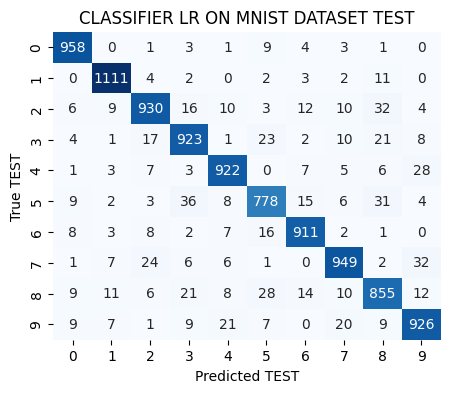

In [ ]:
run_train_lr(max_iter_=CONFIG.LR_MAX_ITER)

# Importa un modello DenseNet da torchvision <br>
[Documentazione](https://pytorch.org/hub/pytorch_vision_densenet/) <br>
**Descrizione Modello nella documentazione** <br>

Dense Convolutional Network (DenseNet), connects each layer to every other layer in a feed-forward fashion. Whereas traditional convolutional networks with L layers have L connections – one between each layer and its subsequent layer – our network has L(L+1)/2 direct connections. <br>
For each layer, the feature-maps of all preceding layers are used as inputs, and its own feature-maps are used as inputs into all subsequent layers. DenseNets have several compelling advantages: they alleviate the vanishing-gradient problem, strengthen feature propagation, encourage feature reuse, and substantially reduce the number of parameters <br>

**Dati utilizzati dal modello**<br>

All pre-trained models expect input images normalized in the same way, i.e. mini-batches of 3-channel RGB images of shape (3 x H x W), where H and W are expected to be at least 224. The images have to be loaded in to a range of [0, 1] and then normalized using mean = [0.485, 0.456, 0.406] and std = [0.229, 0.224, 0.225].















**DEFINISCO LA CLASSE DEL MODELLO DI RETE CONV DA ADDESTRARE** <br>

### Dimensione in input/output
Input: $N$, $C_{in}$, H, W  \\
Layer Convoluzionali: $[N, n\_filters, H- (Kernel\_size -1), W-(Kernel\_size -1)]$ \\
Max Pool 2d: Output: $[N, C_{in}, \frac{H}{2}, \frac{W}{2}]$

### Parameteri

Layer Convoluzionali: $(((Kernel_{w} * Kernel_{h})*n_{canali})+1)*n_{filtri}$ \\
Layer lineari : $(input + 1) * output$ \\
Max Pool 2d: 0

**Creo la rete e la sposto su Gpu con il metodo to()**

**Allenare la CNN..**

In [ ]:
# 1. Setup del modello e dataset
# Carichiamo DenseNet pre-addestrato
# model = densenet121(weights=DenseNet121_Weights.DEFAULT)
model = torch.hub.load('pytorch/vision:v0.10.0', 'densenet121', pretrained=True)
model

Downloading: "https://github.com/pytorch/vision/zipball/v0.10.0" to /root/.cache/torch/hub/v0.10.0.zip
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 62.5MB/s]


DenseNet(
  (features): Sequential(
    (conv0): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
    (norm0): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (relu0): ReLU(inplace=True)
    (pool0): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
    (denseblock1): _DenseBlock(
      (denselayer1): _DenseLayer(
        (norm1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu1): ReLU(inplace=True)
        (conv1): Conv2d(64, 128, kernel_size=(1, 1), stride=(1, 1), bias=False)
        (norm2): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu2): ReLU(inplace=True)
        (conv2): Conv2d(128, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      )
      (denselayer2): _DenseLayer(
        (norm1): BatchNorm2d(96, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (relu

#**Trasformazioni per il dataset** <br>


#**ARCHITETTURA DEL MODELLO XAI di tipo DenseNet Modificato** <br>

Partiamo dal modello DensNet addestrato su imagenet e facciamo le seguenti modifiche alla struttura : <br>


1. **Modifica il numero di classi dell'ultimo layer**
Trasformiamo quella rete in una rete che vada per ImageNet per questo tagliamo via l'ultimo strato di classificazione come si dovrà fare anche nel progetto finale che lavora con il Mnist.(dataset di cifre) e lo facciamo uscire invece che con il numero di classi di ImageNet con il numero di classi di LabelFaceINtheWild <br>

2. **Freeziamo tutti i parametri della rete in modo che non siano modificati dal nostro train**. <br>
Facciano transferLearning ovvero scarichiamo il modello DenseNet e usianmo i suoi parametri freezati perchè l'assunto è che pur essendo stato addestrato su un altro dataset potrebbe aver imparato qualcosa d'interessante su cosa e come vedere. Il modello è stato addestrato su ImageNet ma io lo voglio riaddestrare sul nostro dataset . <br>
Il modello viene tagliato a partire dall'ultimo strato convolutivo e verrà addestrato a imparare a classificare sul LabelFaceInTheWildPeople <br>
Per velocizzare il tutto tengo buoni i primi strati convolutivi originali del DenseNet che sono freezati non verranno addestrati e modificati tranne l'ultimo strato aggiunto da noi<br>

**APPUNTI INTERPRETAZIONE DEL CODICE** <br>
**1. DIMENSIONI DEI TENSORI IN INPUT** <br>

Il valore 1024 viene dall’architettura della DenseNet121 pre-addestrata, non dai pixel dell’immagine.

Quando dai alla DenseNet un tensore 3 × 128 × 128, l’immagine attraversa molti layer convoluzionali, pooling e dense blocks. A ogni passaggio le dimensioni spaziali (altezza × larghezza) vengono ridotte, mentre il numero di canali/feature viene trasformato e aumentato. Alla fine, la rete fa una sintesi delle feature visive e restituisce un vettore di dimensione fissa pari a 1024.

In forma semplificata:

3 × 128 × 128
      ↓
Convoluzioni e Dense Blocks
      ↓
Mappe di feature interne
      ↓
Global Average Pooling
      ↓
Vettore di 1024 feature
      ↓
Linear(1024, 10)
Il Global Average Pooling è il passaggio chiave: prende ciascuna mappa di feature finale e ne calcola una sintesi, normalmente una media. Se alla fine il backbone ha 1024 mappe di feature, il pooling produce un numero per ciascuna mappa, quindi un vettore di 1024 valori.

Per questo, il layer originale della DenseNet aveva una struttura concettuale simile a:

nn.Linear(1024, 1000)
per classificare le 1000 classi di ImageNet. Tu lo hai sostituito con:

nn.Linear(1024, 10)
per classificare le 10 cifre di MNIST. Hai cambiato solo il numero di output, mentre le 1024 feature in ingresso al classificatore sono determinate dal backbone DenseNet121.

Un punto utile: grazie al pooling finale, lo stesso backbone può spesso elaborare immagini con dimensioni spaziali differenti, purché sufficientemente grandi e compatibili con l’architettura. Il vettore finale rimane comunque lungo 1024.

**2. INTERPRETAZIONE DEI VALORI IN OUTPUT** <br>

Francesco. I 10 valori in uscita dal layer Linear(1024, 10) corrispondono effettivamente alle 10 classi MNIST, da 0 a 9.

La precisazione importante è questa: l’output diretto del modello non è ancora la probabilità di ogni classe, ma un insieme di logits.

Per esempio, il modello potrebbe produrre:

[-1.2, 0.4, 3.8, 0.1, -0.7, 1.0, -2.3, 0.5, 0.9, -0.4]
il primo valore è lo score associato alla classe 0;
il secondo alla classe 1;
...
il decimo alla classe 9.
Lo score più alto è 3.8, che si trova in posizione 2: la classe predetta è quindi la cifra 2.

Quando usi:

_, predicted_ = torch.max(outputs_, dim=1)
stai estraendo l’indice del logit più alto, cioè la classe scelta dal modello.

Se volessi interpretare quei valori come probabilità, dovresti applicare softmax: trasforma i 10 logits in valori compresi tra 0 e 1 la cui somma è 1. Ad esempio:

Classe 0 → 0,01
Classe 1 → 0,03
Classe 2 → 0,79
...
Con CrossEntropyLoss, però, non devi applicare softmax manualmente durante il training: la loss riceve direttamente i logits e include internamente il passaggio necessario, in modo numericamente stabile.

La scelta della classe resta identica sia usando logits sia usando probabilità softmax, perché softmax mantiene l’ordine dei valori: il valore più grande resta quello della classe predetta.

Nel tuo test, per calcolare accuracy e confusion matrix, ti bastano gli indici predetti ottenuti con torch.max: non serve calcolare le probabilità.

Quale informazione aggiuntiva potresti ottenere dalle probabilità softmax, oltre alla classe predetta


**TRAIN CON 10 EPOCHE**

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 487kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.52MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 7.09MB/s]


START TRAIN DATALOADER
END TRAIN DATALOADER
START TEST DATALOADER
END TEST DATALOADER
Downloading: "https://github.com/pytorch/vision/zipball/v0.10.0" to /root/.cache/torch/hub/v0.10.0.zip
Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 181MB/s]


num_classes  10
Parametri totali: 6,964,106
Parametri congelati: 6,953,856
Parametri addestrabili: 10,250
classifier.weight torch.Size([10, 1024])
classifier.bias torch.Size([10])
[1,   901] loss: 38.952
[2,   901] loss: 19.287
[3,   901] loss: 16.753
[4,   901] loss: 15.757
[5,   901] loss: 14.735
[6,   901] loss: 14.306
[7,   901] loss: 13.762
[8,   901] loss: 14.122
[9,   901] loss: 13.920
[10,   901] loss: 13.494
Train completato
Accuratezza di test (DenseNet Cnn): 0.9506


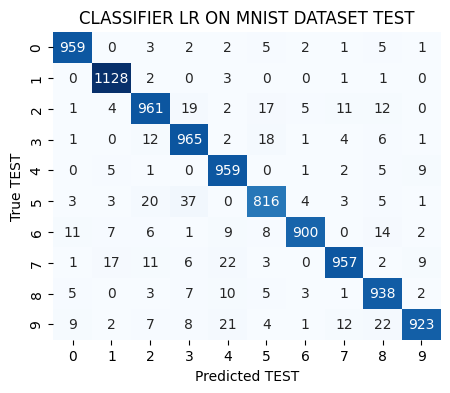

In [ ]:
transform_densenet = transforms.Compose([ # Aumenta altezza e larghezza delle immagini
                                     transforms.Resize((128, 128)),
                                     # Converti in tensore
                                     transforms.ToTensor(),
                                    # espando i canali da 1 a 3
                                    transforms.Lambda(lambda x: x.repeat(3, 1, 1) if x.shape[0] == 1 else x), # Espande a 3 canali
                                    # normalizzazione delle img
                                    transforms.Normalize(
                                    mean=   [0.485, 0.456, 0.406],
                                    std=[0.229, 0.224, 0.225]
                                    )
                                    ])

mnist_trainvalset_cnn = datasets.MNIST(root='./data', train=True, download=True, transform=transform_densenet)
mnist_testset_cnn = datasets.MNIST(root='./data', train=False, download=False, transform=transform_densenet)

# mettere nella parametrizzazione
train_size = 54000
val_size = 6000

# Usiamo generator per fissare la seed e rendere la separazione riproducibile
train_dataset_cnn, val_dataset_cnn = random_split( mnist_trainvalset_cnn,
                                                   [train_size, val_size],
                                                   # Seed per riproducibilità
                                                   generator=torch.Generator().manual_seed(SEED)  )



images_labels = mnist_trainvalset_cnn


print("START TRAIN DATALOADER")
# trainval_loader = DataLoader(mnist_trainvalset, batch_size=len(mnist_trainvalset), shuffle=False)
train_loader_cnn = DataLoader(train_dataset_cnn, batch_size=BATCH_SIZE,shuffle=True)
print("END TRAIN DATALOADER")
print("START TEST DATALOADER")
test_loader_cnn = DataLoader(mnist_testset_cnn, batch_size=BATCH_SIZE,shuffle=False)
print("END TEST DATALOADER")

model = torch.hub.load('pytorch/vision:v0.10.0', 'densenet121', pretrained=True)


for param in model.parameters():
    param.requires_grad = False

# Modifichiamo l'ultimo layer per il numero corretto di classi
num_classes = len(mnist_trainvalset_cnn.class_to_idx)
# num_classes = len(mnist_trainvalset_cnn.classes)
print("num_classes " , num_classes)

num_ftrs = model.classifier.in_features
model.classifier = nn.Linear(num_ftrs, num_classes)
# model
# ultimo strato 10 classi

total_params = sum(p.numel() for p in model.parameters())

trainable_params = sum(p.numel() for p in model.parameters()
    if p.requires_grad)

print(f"Parametri totali: {total_params:,}")
print(f"Parametri congelati: {total_params - trainable_params:,}")
print(f"Parametri addestrabili: {trainable_params:,}")
for name, param in model.named_parameters():
    if param.requires_grad:
        print(name, param.shape)

loss_function = nn.CrossEntropyLoss()
# Setto optimzers lo stocastic gradient descend
# un learning rate=0.05
# il parametro momentum=0.09
# optimizer = torch.optim.SGD(model.parameters(), lr=0.005, momentum=0.9)
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# num_epochs=5
num_epochs=10
run_train_cnn(model,train_loader_cnn,device,optimizer,loss_function,num_epochs_=num_epochs)

y_pred, y_true, y_pred_desc, y_true_desc = run_test_cnn(model,mnist_testset_cnn,test_loader_cnn,device)

test_accuracy_cnn_start = accuracy_score(y_true,y_pred)
print(f"Accuratezza di test (DenseNet Cnn): {test_accuracy_cnn_start}")
plot_confusion_matrix_cnn(y_true,y_pred, "CLASSIFIER LR ON MNIST DATASET " , "TEST")






**TRAIN PRODUZIONE CON 5 EPOCHE**

100%|██████████| 9.91M/9.91M [00:01<00:00, 5.37MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 129kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.05MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 10.6MB/s]


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth


100%|██████████| 30.8M/30.8M [00:00<00:00, 178MB/s]
12:53:23 - INFO - [run_main_cnn] - num_classes 10
12:53:23 - INFO - [run_main_cnn] - Parametri totali: 6,964,106
12:53:23 - INFO - [run_main_cnn] - Parametri congelati: 6,953,856
12:53:23 - INFO - [run_main_cnn] - Parametri addestrabili: 10,250
12:53:23 - INFO - [run_main_cnn] - classifier.weight , torch.Size([10, 1024])
12:53:23 - INFO - [run_main_cnn] - classifier.bias , torch.Size([10])
13:01:58 - INFO - [run_train_cnn] - Train completato
13:02:15 - INFO - [run_main_cnn] - Accuratezza di test (DenseNet Cnn): 0.9679


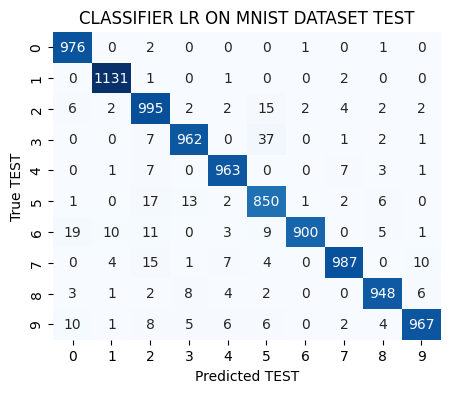

In [ ]:
num_epochs=5
model_cnn , optimizer_cnn ,loss_cnn = run_main_cnn(num_epochs_=num_epochs)
# 08:09:46 - INFO - [run_main_cnn] - Accuratezza di test (DenseNet Cnn): 0.9496
# 08:02:54 - INFO - [run_main_cnn] - Accuratezza di test (DenseNet Cnn): 0.9489
# RISULTATO CON FLAG BATCHNORM EVAL TRUE
# 08:13:23 - INFO - [run_main_cnn] - Accuratezza di test (DenseNet Cnn): 0.9732
# RISULTATO CON FLAG BATCHNORM EVAL TRUE e RELUINPLACE TRUE
# 08:30:57 - INFO - [run_main_cnn] - Accuratezza di test (DenseNet Cnn): 0.9732

**SALVO I PESI DEL MODELLO PER NON RIFARE IL TRAIN**
oppure il carico pesi e optimizer salvati prima

In [ ]:
flag_save=True
num_epochs=5
!ls
if flag_save:

    logger.info(f"{type(loss_cnn)}")
    checkpoint_start = { 'epoch': num_epochs,                            # Epoca corrente
              'model_state_dict': model_cnn.state_dict(),     # Pesi del modello
              'optimizer_state_dict': optimizer_cnn.state_dict() # Stato dell'ottimizzatore (es. momentum, learning rate)
              # 'loss': loss_cnn,                       # Ultimo valore di loss
              }

    # Salvi il dizionario in un unico file
    torch.save(checkpoint_start, 'checkpoint_fase_0.pt')
    logger.info("Checkpoint iniziale salvato con successo!")
else:

    # 1. Inizializzi l'architettura del modello e l'ottimizzatore come al solito
    model = torch.hub.load('pytorch/vision:v0.10.0', 'densenet121', pretrained=True)
    # Le classi devono essere modificati subito
    # anche prima dell'optimizer altrimenti il load fallisce
    # Sia modello sia optimizer devo essere settati con 10 classi in uscita

    # ma il congelamento della backbone va fatto dopo
    # for param in model.parameters():
    #     param.requires_grad = False
    mnist_trainvalset_cnn,_ = load_dataset_cnn()
    # Modifichiamo l'ultimo layer per il numero corretto di classi
    num_classes = len(mnist_trainvalset_cnn.class_to_idx)
    num_ftrs = model.classifier.in_features
    model.classifier = nn.Linear(num_ftrs, num_classes)

    logger.info(f"Numero di classi nel dataset: {num_classes}")

    optimizer = torch.optim.Adam(model.parameters(), lr=0.001) # Usa il tuo ottimizzatore

    for param in model.parameters():
        param.requires_grad = False

    checkpoint = { 'epoch': num_epochs,                            # Epoca corrente
                     'model_state_dict': model.state_dict(),     # Pesi del modello
                    'optimizer_state_dict': optimizer.state_dict(), # Stato dell'ottimizzatore (es. momentum, learning rate)                    # Ultimo valore di loss
                  }



    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

    # 2. Carichi il dizionario del checkpoint
    checkpoint = torch.load('checkpoint_fase_0.pt', map_location=device)

    # 3. Ripristini lo stato di modello ed ottimizzatore
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])

    # 4. Recuperi l'epoca e la loss da cui ripartire
    start_epoch = checkpoint['epoch'] + 1
    # last_loss = checkpoint['loss']
    model.to(device)

    # logger.info(f"Ripristinato checkpoint. Riparto dall'epoca {start_epoch} (Ultima loss: {last_loss:.4f})")
    logger.info(f"Ripristinato checkpoint. Riparto dall'epoca {start_epoch} ")




data  sample_data


13:04:28 - INFO - [<cell line: 0>] - <class 'torch.nn.modules.loss.CrossEntropyLoss'>
13:04:28 - INFO - [<cell line: 0>] - Checkpoint iniziale salvato con successo!


**VISUALIZZO UNA GRIGLIA DI IMMAGINI**

13:12:26 - WARNING - [_normalize_image_array] - Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..1.0000000236034394].


10000 immagini, 10 identità


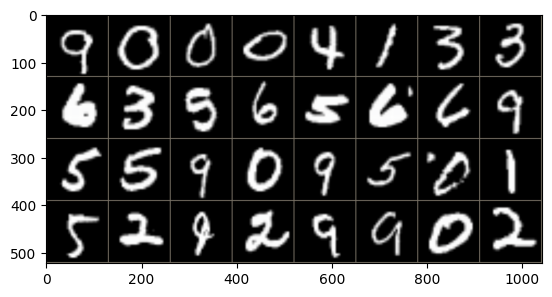

,Ground Truth,Prediction
0,9 - nine,9 - nine
1,0 - zero,0 - zero
2,0 - zero,0 - zero
3,0 - zero,0 - zero
4,4 - four,4 - four


In [ ]:
_, mnist_testset_cnn = load_dataset_cnn()
images, labels = get_images_labels(mnist_testset_cnn)
df, gt_pred_desc , gt_label_desc , predicted = run_predict_on_image(mnist_testset_cnn,images,labels)
df.head()

**VISUALIZZO UNA SINGOLA IMMAGINE**

13:12:44 - WARNING - [_normalize_image_array] - Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.053115898461357e-09..0.9960784730911255].


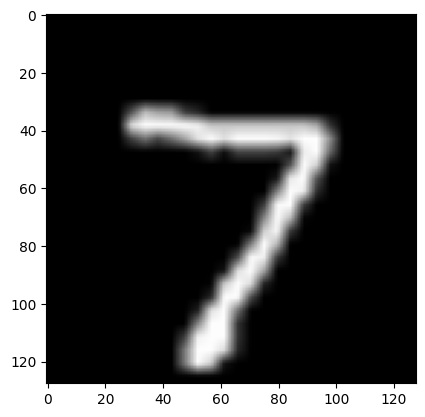

,Ground Truth,Prediction
0,7 - seven,7 - seven


In [ ]:
images, labels = get_images_labels(mnist_testset_cnn,flag_data_loader=False,idx_dataset=0)
df, gt_pred_desc , gt_label_desc , predicted = run_predict_on_image(mnist_testset_cnn,images,labels)
df.head()

**SPIEGAZIONE CON CAPTUM**

In [ ]:
mnist_testset_cnn.class_to_idx['0 - zero']
mnist_testset_cnn.class_to_idx.values()

idx_to_class = {v: k for k, v in mnist_testset_cnn.class_to_idx.items()}
key = idx_to_class[int('0')]
key


'0 - zero'

In [ ]:
idx_to_class = {v: k for k, v in mnist_testset_cnn.class_to_idx.items()}
list_to_class = [k for k, v in mnist_testset_cnn.class_to_idx.items()]
key = idx_to_class[int('0')]
keys = idx_to_class.keys()
class_values = ['0','1','2','3','4','5','6','7','8','9']
print(f"idx_to_class {idx_to_class}")
print(f"keys {keys}")
print(f"list_to_class {list_to_class}")

for i in keys:
  print(f"{i}")
  # indices_for_identity = [i for i, (path, label) in enumerate(dataset_.[]) if label == target_class_id]

idx_to_class {0: '0 - zero', 1: '1 - one', 2: '2 - two', 3: '3 - three', 4: '4 - four', 5: '5 - five', 6: '6 - six', 7: '7 - seven', 8: '8 - eight', 9: '9 - nine'}
keys dict_keys([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
list_to_class ['0 - zero', '1 - one', '2 - two', '3 - three', '4 - four', '5 - five', '6 - six', '7 - seven', '8 - eight', '9 - nine']
0
1
2
3
4
5
6
7
8
9


In [ ]:
def get_inference_error_images(dataset_,model_,class_search = '0 - zero'):
    # name_search = "George_W_Bush"
    # name_search = "Farouk_al-Sharaa"
    name_search = "0"
    label = labels[0]
    # name_search = 'Milo_Djukanovic'
    target_class_id = dataset.class_to_idx[name_search]
    logger.info(f"target_class_id {target_class_id}")
    logger.info(f"target_class_id {label}")

    dataset_.class_to_idx[class_search]
    dataset_.class_to_idx.values()

    idx_to_class = {v: k for k, v in dataset_.class_to_idx.items()}
    key = idx_to_class[int('0')]

    class_values = ['0','1','2','3','4','5','6','7','8','9']
    print(f"idx_to_class {idx_to_class}")
    print(f"key {key}")



    indices_for_identity = [i for i, (path, label) in enumerate(dataset_.samples) if label == target_class_id]
    print(len(indices_for_identity))
    print(indices_for_identity)   # es. [4021, 4022, 4023] — le foto di quella persona

    model.eval()
    # name_search = "Farouk_al-Sharaa"
    name_search = "George_W_Bush"
    img_index_wrong = None
    for i in indices_for_identity:            # solo le foto di Milo_Djukanovic
        img, label = dataset[i]
        # print(f"i {i} label {label}")
        img_input = img.unsqueeze(0).to(device)
        with torch.no_grad():
            output = model(img_input)
            pred = output.argmax(dim=1).item()
            # trovata la foto che il modello sbaglia
            # if pred != label and i not in (2660,2788,2876) and name_search == dataset.classes[pred]:
            if pred != label and name_search == dataset.classes[pred]:
                img_index_wrong = i
                predicted_wrong = pred
                break

    # indice di Bush che sbaglia con Farouk
    print(img_index_wrong, dataset.classes[label], dataset.classes[predicted_wrong])

**INIZIALIZZO I METODI DI SPIEGAZIONE**

In [ ]:
# 3. Spiegazioni con Captum
def run_inference_on_image(dataset_,model_,face_idx = 0):
    model_.eval()

    input_img, label = dataset_[face_idx]
    print(f"label {label}")
    input_img = input_img.unsqueeze(0).to(device)
    label = torch.tensor([label]).to(device)

    # Ottieni il nome della classe
    class_names = list(dataset_.class_to_idx.keys())
    class_name = class_names[label.item()]

    print(f"Analizziamo l'immagine {face_idx} con etichetta: {class_name}")

    with torch.no_grad():
        output = model_(input_img)
        pred = output.argmax(dim=1).item()
        pred_name = class_names[pred]

        str_title = f'Immagine Originale\nTrue: {class_name}\nPred: {pred_name}'

    print(f"{str_title}")
    return input_img , str_title





def visualize_attributions(orig_img, attributions, title , title_org):
    attr_map = attributions.squeeze().cpu().detach().numpy()
    if len(attr_map.shape) > 2:
        attr_map = np.abs(attr_map).sum(axis=0)  # Somma sui canali

    # Normalizzazione
    attr_map = (attr_map - attr_map.min()) / (attr_map.max() - attr_map.min() + 1e-8)

    plt.figure(figsize=(10, 4))
    plt.subplot(1, 2, 1)
    # Denormalizziamo l'immagine per la visualizzazione
    img_show = orig_img.squeeze().cpu().detach().numpy()
    img_show = np.transpose(img_show, (1, 2, 0))
    img_show = img_show * np.array([0.229, 0.224, 0.225]) + np.array([0.485, 0.456, 0.406])
    img_show = np.clip(img_show, 0, 1)

    plt.imshow(img_show)
    # plt.title('Immagine Originale')
    plt.title(title_org)
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(attr_map, cmap='hot')
    plt.title(title)
    plt.axis('off')
    plt.colorbar()
    plt.show()

label 7
Analizziamo l'immagine 0 con etichetta: 7 - seven
Immagine Originale
True: 7 - seven
Pred: 7 - seven


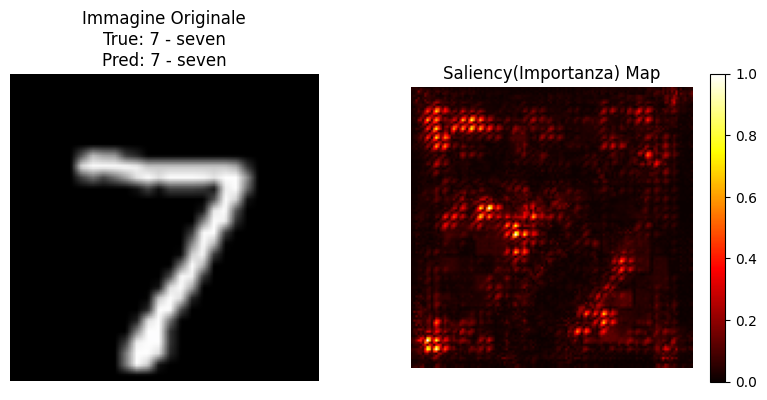

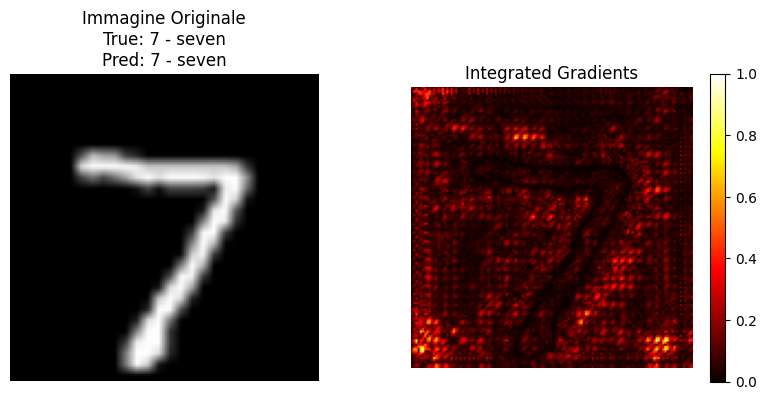

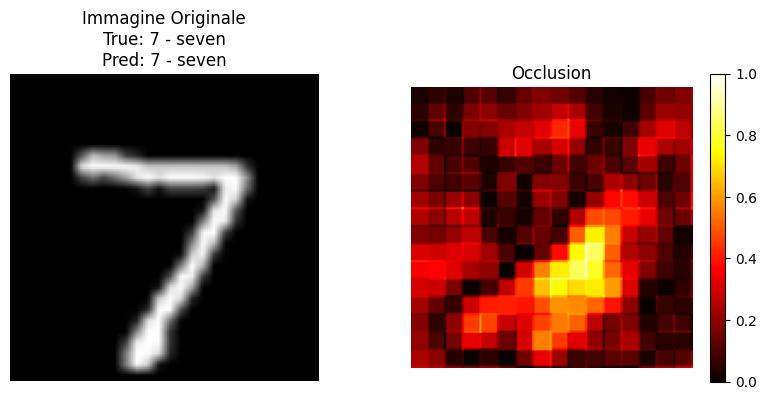

In [ ]:
input_img_org , str_title_org = run_inference_on_image(mnist_testset_cnn,model,face_idx = 0)

# Inizializzazione dei metodi di spiegazione
saliency = Saliency(model)
ig = IntegratedGradients(model)
occlusion = Occlusion(model)




# Calcolo e visualizzazione delle attribuzioni
# Saliency
saliency_attr = saliency.attribute(input_img_org, target=label)
visualize_attributions(input_img_org, saliency_attr, 'Saliency(Importanza) Map',str_title_org)

# Integrated Gradients
ig_attr = ig.attribute(input_img_org, target=label, n_steps=50)
visualize_attributions(input_img_org, ig_attr, 'Integrated Gradients', str_title_org)

# Occlusion
occlusion_attr = occlusion.attribute(input_img_org,
                                   target=label,
                                   strides=(3, 8, 8),
                                   sliding_window_shapes=(3,15,15),
                                   baselines=0)
visualize_attributions(input_img_org, occlusion_attr, 'Occlusion', str_title_org)